# Home Credit | 模型复核规则与成本取舍分析

基于前一份历史回测输出的 Week 55–77 逐笔预测，研究如何将无需即时真实标签的监控信号转化为透明的模型复核规则，并通过历史回放比较误复核和业务暴露。

**研究流程：** 监控指标 → 候选复核规则 → 历史回放 → Pareto 权衡 → 成本偏好情景分析。

**重要边界：** Week 64 仅作为利用成熟真实标签进行**事后评价**的近似变化点，不是当时的无标签规则输入。候选规则的比较也属于单一历史案例内的探索性分析，而不是独立的前瞻部署验证。


# 1. 方法选择：透明复核规则

当前回测样本主要包含一个明显的历史校准变化事件，无法提供足够多相互独立的失准/未失准事件以训练并评估监督式监控分类器。因此采用可审计的规则结构，将预测分布、预测概率和申请量等代理信号映射为复核建议。

**优势：** 阈值、持续时间和证据组合都可以解释与回放；不依赖大量标记好的历史失准事件。

**局限：** 阈值敏感、代理信号未必对应真实校准恶化，单一案例的优秀结果不能证明未来可以泛化。研究结论限定为本次历史样本中不同候选政策的取舍，并不宣称找到了可以直接部署的最优监控规则。


# 2. 候选阈值、组合规则与成本偏好

| 对象 | 作用 | 设计方式 |
|---|---|---|
| 异常阈值 | 定义单个监控信号何时偏离参考值 | 探索宽松、中等、严格三个档位 |
| 信号组合 | 决定多少种证据共同支持复核 | 至少 2/3 项异常、特定信号组合、连续持续周数 |
| 成本参数 K | 反映误复核与业务暴露的相对偏好 | 在 Pareto 结果上做情景分析，而非拟合历史事件 |

本实验不训练信号的连续权重，避免在单一历史事件上拟合难以验证的复杂组合。候选阈值及规则应视为**探索性政策集合**，不是经过独立样本选择的生产阈值。

`等价成本 = 业务暴露量 + K × 误复核次数`，其中 K 表示机构主观赋予一次误复核的等价业务暴露笔数；它不是从数据中估计的真实货币成本。


# 3. 数据与时间角色

输入为历史回测中冻结参考模型在 W55–77 的预测结果。

- `target`：只用于事后确认失准起点；
- `predicted_pd`、预测分布、高风险预测占比、申请量：用于模拟当时可观察的监控信息。

W55 被用作预测输出的初始监控参考周，只因为它是模拟上线监控期的起点，并不意味着在当时已经知道 W55 的校准水平。

申请量则使用 W35–54 的历史每周申请量作为部署前已经可见的业务基准。


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/HomeCredit_Project")
MONITOR_PATH = ROOT / "artifacts/fit5145/nb02_history_backtest/monitor_predictions_week55_77.parquet"
TRAIN_PATH = ROOT / "artifacts/_auto_extracted/Notebook_5/nb05_clean_split_outputs/clean_split/train_clean.parquet"
OUT = ROOT / "artifacts/fit5145/nb03_review_tradeoff_v6"
OUT.mkdir(parents=True, exist_ok=True)

monitor = pd.read_parquet(MONITOR_PATH)
monitor = monitor.loc[monitor["WEEK_NUM"].between(55, 77)].copy()

print(f"监控样本：{len(monitor):,} 笔")
print(f"时间范围：W{monitor.WEEK_NUM.min()}–W{monitor.WEEK_NUM.max()}")

Mounted at /content/drive
监控样本：245,182 笔
时间范围：W55–W77


# 4. 使用成熟标签进行事后变化点评价

此处仅为事后评价使用成熟标签。

其目的是建立回顾性评价基准：

> **回头看，校准表现大约从哪一周开始发生结构性变化？**

针对不同候选变化点比较前后 O/E。

O/E = 实际违约数 / 预测违约数。

如果 O/E 接近 1，说明整体预测概率和实际违约水平较接近；明显偏离 1，说明校准出现系统性偏差。


事后最强变化点：W64


,break_week,left_oe,right_oe,loglik_gain
0,64,1.055412,0.632451,244.625593
1,65,1.042315,0.609649,244.432861
2,66,1.036562,0.604687,238.664819
3,67,1.031001,0.605540,227.870127
4,68,1.028089,0.605696,222.469599
5,69,1.026877,0.604562,221.211730
6,70,1.022043,0.607151,210.345610
7,63,1.060774,0.684428,201.197705
8,71,1.013023,0.610262,191.713925
9,72,0.997192,0.613158,161.280258


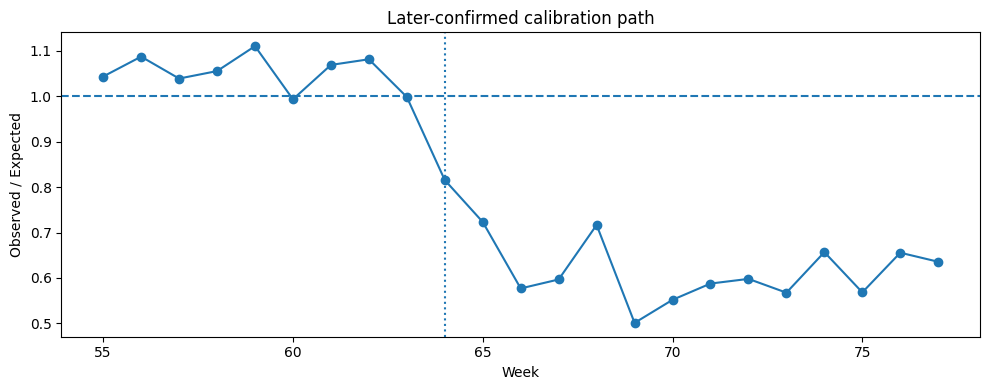

In [2]:
weekly_truth = (
    monitor.groupby("WEEK_NUM")
    .agg(
        n=("target", "size"),
        observed=("target", "sum"),
        expected=("predicted_pd", "sum"),
    )
    .reset_index()
)
weekly_truth["oe"] = weekly_truth["observed"] / weekly_truth["expected"]

def segment_ll(df):
    ratio = df["observed"].sum() / df["expected"].sum()
    mu = np.clip(ratio * df["expected"].to_numpy(), 1e-12, None)
    y = df["observed"].to_numpy()
    return np.sum(y * np.log(mu) - mu), ratio

null_ll, _ = segment_ll(weekly_truth)
rows = []

for tau in weekly_truth["WEEK_NUM"]:
    left = weekly_truth[weekly_truth["WEEK_NUM"] < tau]
    right = weekly_truth[weekly_truth["WEEK_NUM"] >= tau]
    if len(left) < 3 or len(right) < 3:
        continue

    ll_l, oe_l = segment_ll(left)
    ll_r, oe_r = segment_ll(right)

    rows.append({
        "break_week": int(tau),
        "left_oe": oe_l,
        "right_oe": oe_r,
        "loglik_gain": ll_l + ll_r - null_ll,
    })

change_points = (
    pd.DataFrame(rows)
    .sort_values("loglik_gain", ascending=False)
    .reset_index(drop=True)
)

TAU = int(change_points.iloc[0]["break_week"])

print(f"事后最强变化点：W{TAU}")
display(change_points.head(10))

plt.figure(figsize=(10, 4))
plt.plot(weekly_truth["WEEK_NUM"], weekly_truth["oe"], marker="o")
plt.axhline(1, linestyle="--")
plt.axvline(TAU, linestyle=":")
plt.xlabel("Week")
plt.ylabel("Observed / Expected")
plt.title("Later-confirmed calibration path")
plt.tight_layout()
plt.show()

## 4.1 事后变化点分析结果

本数据中：

- 最强变化点是 **W64**；
- W64 前整体 O/E 约为 **1.055**；
- W64 后整体 O/E 约为 **0.632**；
- W65 的变化点得分与 W64 很接近。

因此按结果将其表述为：

> **校准恶化大约从 W64 开始，W64 被用作本案例的事后评价基准。**

下节计算的无标签复核规则不使用 `target`。

也就是说：

**成熟标签负责建立“后来确认的事实”；无标签信号负责模拟“当时是否值得启动复核”。**


# 5. 部署时可观察的四个监控信号

使用四种简单代理信号：

1. **Score PSI**：预测概率分布相对 W55 的变化；
2. **平均预测概率变化**；
3. **高风险预测占比变化**；
4. **申请量变化**：相对 W35–54 历史周申请量中位数。

这些信号都不是“模型已经失准”的证明。

它们只是：

> 在真实结果尚未成熟时，当时可以看到的间接证据。


In [3]:
# W55：预测输出监控的初始参考
ref = monitor.loc[monitor["WEEK_NUM"] == 55, "predicted_pd"].astype(float)
ref_mean = ref.mean()
high_cut = ref.quantile(0.90)
ref_high_share = (ref >= high_cut).mean()

# W35–54：部署前业务量历史
hist = pd.read_parquet(TRAIN_PATH, columns=["WEEK_NUM"])
ref_volume = (
    hist.loc[hist["WEEK_NUM"].between(35, 54)]
    .groupby("WEEK_NUM")
    .size()
    .median()
)
del hist

def psi(reference, current, bins=10):
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf

    r = pd.cut(reference, edges, include_lowest=True).value_counts(normalize=True, sort=False)
    c = pd.cut(current, edges, include_lowest=True).value_counts(normalize=True, sort=False)

    r = np.clip(r.to_numpy(float), 1e-6, None)
    c = np.clip(c.to_numpy(float), 1e-6, None)

    return float(np.sum((c - r) * np.log(c / r)))

signal_rows = []

for week, g in monitor.groupby("WEEK_NUM"):
    if week == 55:
        continue

    p = g["predicted_pd"].astype(float)
    high_share = (p >= high_cut).mean()

    signal_rows.append({
        "WEEK_NUM": int(week),
        "score_psi": psi(ref, p),
        "mean_pd_shift": abs(p.mean() / ref_mean - 1),
        "high_risk_share_shift": abs(high_share / ref_high_share - 1),
        "volume_shift": abs(len(g) / ref_volume - 1),
        "application_volume": len(g),
    })

signals = pd.DataFrame(signal_rows)

print(f"W35–54 每周申请量中位数：{ref_volume:,.1f}")
display(signals)

W35–54 每周申请量中位数：22,669.5


,WEEK_NUM,score_psi,mean_pd_shift,high_risk_share_shift,volume_shift,application_volume
0,56,0.001956,0.071142,0.085286,0.246918,17072
1,57,0.002799,0.085188,0.121662,0.196233,18221
2,58,0.010213,0.130185,0.185685,0.213966,17819
3,59,0.007170,0.107176,0.127410,0.217936,17729
4,60,0.012149,0.134199,0.162255,0.300205,15864
5,61,0.020101,0.188811,0.245369,0.313262,15568
6,62,0.018018,0.182075,0.218699,0.242859,17164
7,63,0.000836,0.008826,0.025703,0.367564,14337
8,64,0.007161,0.057068,0.112873,0.547057,10268
9,65,0.038198,0.235510,0.347182,0.812171,4258


## 5.1 从连续监控指标到复核决策

下方生成的 PSI、平均预测概率变化、高风险占比变化和申请量变化，均为可在标签成熟前观察的代理信号。复核规则通过阈值、组合逻辑与连续周数，将这些数值映射为可回放的复核触发事件。


# 6. 候选复核规则

### 6.1 三档探索性阈值

| 信号 | 宽松 | 中等 | 严格 |
|---|---:|---:|---:|
| Score PSI | 0.05 | 0.10 | 0.20 |
| 平均预测概率变化 | 5% | 10% | 15% |
| 高风险占比变化 | 20% | 35% | 50% |
| 申请量变化 | 20% | 30% | 40% |

对每个信号组合分别评估连续 **1、2、3 周** 的触发要求。

### 6.2 两类政策

**单信号筛查基线：** 预测分布、平均预测概率、高风险占比、申请量任意一个信号单独触发，或任意一项异常即触发，用来观察单一证据在这一历史案例中的表现。

**多证据复核政策：** 至少两项异常、至少三项异常、预测分布和另一项异常、模型输出至少两项异常、模型输出异常与申请量异常。

共 **10 种规则结构 × 3 档阈值 × 3 个持续时间 = 90 条候选规则**。比较结果仅对本次已评估的候选集合成立。


In [4]:
THRESHOLDS = {
    "宽松": {"score_psi": 0.05, "mean_pd_shift": 0.05, "high_risk_share_shift": 0.20, "volume_shift": 0.20},
    "中等": {"score_psi": 0.10, "mean_pd_shift": 0.10, "high_risk_share_shift": 0.35, "volume_shift": 0.30},
    "严格": {"score_psi": 0.20, "mean_pd_shift": 0.15, "high_risk_share_shift": 0.50, "volume_shift": 0.40},
}

BASELINE_RULES = [
    "只看预测分布",
    "只看平均预测概率",
    "只看高风险占比",
    "只看申请量",
    "任意1项异常",
]

PRIMARY_RULES = [
    "至少2项异常",
    "至少3项异常",
    "预测分布+至少另1项",
    "模型输出至少2项异常",
    "模型输出异常+申请量异常",
]

def flag_table(df, th):
    x = pd.DataFrame({"WEEK_NUM": df["WEEK_NUM"]})
    for col in ["score_psi", "mean_pd_shift", "high_risk_share_shift", "volume_shift"]:
        x[col] = df[col] >= th[col]
    return x

def rule_condition(x, name):
    s = x["score_psi"]
    m = x["mean_pd_shift"]
    h = x["high_risk_share_shift"]
    v = x["volume_shift"]

    total = s.astype(int) + m.astype(int) + h.astype(int) + v.astype(int)
    model_total = s.astype(int) + m.astype(int) + h.astype(int)

    return {
        "只看预测分布": s,
        "只看平均预测概率": m,
        "只看高风险占比": h,
        "只看申请量": v,
        "任意1项异常": total >= 1,
        "至少2项异常": total >= 2,
        "至少3项异常": total >= 3,
        "预测分布+至少另1项": s & ((m.astype(int) + h.astype(int) + v.astype(int)) >= 1),
        "模型输出至少2项异常": model_total >= 2,
        "模型输出异常+申请量异常": (model_total >= 1) & v,
    }[name].to_numpy(bool)

def persistent(values, weeks):
    out = np.zeros(len(values), dtype=bool)
    run = 0
    for i, value in enumerate(values):
        run = run + 1 if value else 0
        out[i] = run >= weeks
    return out

def episode_starts(weeks, ready):
    weeks = np.asarray(weeks)
    ready = np.asarray(ready, bool)
    starts = ready & np.r_[True, ~ready[:-1]]
    return weeks[starts].astype(int).tolist()

volume_by_week = weekly_truth.set_index("WEEK_NUM")["n"].to_dict()

def exposure_until(review_week):
    if pd.isna(review_week):
        weeks = [w for w in volume_by_week if w >= TAU]
    else:
        weeks = range(TAU, int(review_week))
    return int(sum(volume_by_week.get(w, 0) for w in weeks))

results = []
traces = {}

for level, th in THRESHOLDS.items():
    x = flag_table(signals, th)

    for rule_name in BASELINE_RULES + PRIMARY_RULES:
        base = rule_condition(x, rule_name)

        for persistence in [1, 2, 3]:
            ready = persistent(base, persistence)
            key = (rule_name, level, persistence)
            traces[key] = pd.DataFrame({
                "WEEK_NUM": x["WEEK_NUM"],
                "review_ready": ready,
            })

            pre_mask = x["WEEK_NUM"].to_numpy() < TAU
            false_weeks = episode_starts(
                x.loc[pre_mask, "WEEK_NUM"],
                ready[pre_mask],
            )

            post_weeks = x.loc[(x["WEEK_NUM"] >= TAU) & ready, "WEEK_NUM"]
            review_week = post_weeks.min() if len(post_weeks) else np.nan

            results.append({
                "rule_group": "筛查型基线" if rule_name in BASELINE_RULES else "主要多证据政策",
                "rule_name": rule_name,
                "strictness": level,
                "persistence_weeks": persistence,
                "false_review_episodes": len(false_weeks),
                "false_review_start_weeks": ", ".join(map(str, false_weeks)),
                "review_week": review_week,
                "delay_weeks": review_week - TAU if pd.notna(review_week) else np.nan,
                "business_exposure": exposure_until(review_week),
                "missed_by_W77": pd.isna(review_week),
            })

results = pd.DataFrame(results)

print("候选规则总数：", len(results))
print("筛查型基线：", (results["rule_group"] == "筛查型基线").sum())
print("主要多证据政策：", (results["rule_group"] == "主要多证据政策").sum())
print("W77 前未触发复核：", results["missed_by_W77"].sum())

候选规则总数： 90
筛查型基线： 45
主要多证据政策： 45
W77 前未触发复核： 37


# 7. 历史回放评分指标

采用两项主要评价指标：

## 7.1 W64 以前：误复核

如果后来确认模型大约从 W64 才开始明显失准，那么 W64 以前启动的独立复核事件记为误复核。

连续多周保持触发，只算一个独立复核事件。

## 7.2 W64 以后：业务暴露

如果规则到 W65 才启动复核：

- W64 的申请仍然经过已经失准的模型；
- 所以业务暴露就是 W64 的申请量。

如果到 W67 才复核，则暴露包括 W64、W65、W66。

业务暴露不是财务损失，也不是说这些申请全部被错误决策。

它只是：

> **模型已经失准但复核尚未启动期间，仍然经过模型的申请规模。**

## 7.3 为什么 W60 的提前触发不能算“提前成功预测 W64”？

如果 W60 启动了一次复核，但后来发现当时并没有真正失准，这次复核会结束，机构继续监控。

所以 W60 是一次误复核，不是“提前四周发现 W64”。


# 8. 全部规则的 Pareto 分析

Pareto 前沿保留那些无法在误复核次数与业务暴露两项指标上同时被其他候选规则改进的方案。

本次 90 条规则的历史回放中，唯一全局 Pareto 规则为「只看申请量 + 严格 40% 阈值 + 持续 1 周」，对应：W64 前 0 次误复核、W64 当周触发和 0 笔等待暴露。

但这一结果存在明显案例特定性：W63 的申请量偏离约 36.8%，W64 约 54.7%，40% 的阈值恰好位于两者之间。**这不能证明申请量单指标规则已在独立事件上通过验证**，因此后续单独分析有多种证据支持的复核政策。


In [5]:
def pareto(df):
    usable = df.loc[~df["missed_by_W77"]].copy().reset_index(drop=True)
    values = usable[["false_review_episodes", "business_exposure"]].to_numpy(float)
    dominated = np.zeros(len(usable), dtype=bool)

    for i in range(len(usable)):
        for j in range(len(usable)):
            if i == j:
                continue
            if np.all(values[j] <= values[i]) and np.any(values[j] < values[i]):
                dominated[i] = True
                break

    return (
        usable.loc[~dominated]
        .sort_values(["false_review_episodes", "business_exposure"])
        .reset_index(drop=True)
    )

all_pareto = pareto(results)

print("全部90条规则的 Pareto 有效规则数：", len(all_pareto))
display(all_pareto)

w63 = signals.loc[signals["WEEK_NUM"] == 63, "volume_shift"].iloc[0]
w64 = signals.loc[signals["WEEK_NUM"] == 64, "volume_shift"].iloc[0]

print(f"W63 申请量偏离：{w63:.1%}")
print(f"W64 申请量偏离：{w64:.1%}")
print("严格申请量阈值：40%")

全部90条规则的 Pareto 有效规则数： 1


,rule_group,rule_name,strictness,persistence_weeks,false_review_episodes,false_review_start_weeks,review_week,delay_weeks,business_exposure,missed_by_W77
0,筛查型基线,只看申请量,严格,1,0,,64.0,0.0,0,False


W63 申请量偏离：36.8%
W64 申请量偏离：54.7%
严格申请量阈值：40%


# 9. 多证据复核政策的 Pareto 分析

多证据政策与单指标筛查政策具有不同的治理目标。

不是因为多证据规则已经被证明“更准确”。

而是因为它们回答的是不同的治理问题：

> **如果正式模型复核不能只依赖一个代理信号，而需要多个证据共同支持，会出现怎样的决策取舍？**

这类规则至少具有两个优点：

- 不让单一代理变量独自决定正式复核；
- 触发逻辑更容易解释和审计。

但仍然必须承认：

> 多证据规则也可能是事件特定的，本项目没有足够独立事件证明它们可以泛化。


主要多证据 Pareto 规则数： 4
不同 Pareto 成本点数： 2

全部 Pareto 多证据规则：


,rule_group,rule_name,strictness,persistence_weeks,false_review_episodes,false_review_start_weeks,review_week,delay_weeks,business_exposure,missed_by_W77
0,主要多证据政策,至少2项异常,严格,1,0,,65.0,1.0,10268,False
1,主要多证据政策,模型输出异常+申请量异常,严格,1,0,,65.0,1.0,10268,False
2,主要多证据政策,至少2项异常,宽松,1,2,"56, 58",64.0,0.0,0,False
3,主要多证据政策,模型输出异常+申请量异常,宽松,1,2,"56, 58",64.0,0.0,0,False



合并相同成本后的 Pareto 点：


,false_review_episodes,business_exposure,review_week,delay_weeks,policy_count,policies,settings
0,0,10268,65.0,1.0,2,模型输出异常+申请量异常 / 至少2项异常,严格
1,2,0,64.0,0.0,2,模型输出异常+申请量异常 / 至少2项异常,宽松


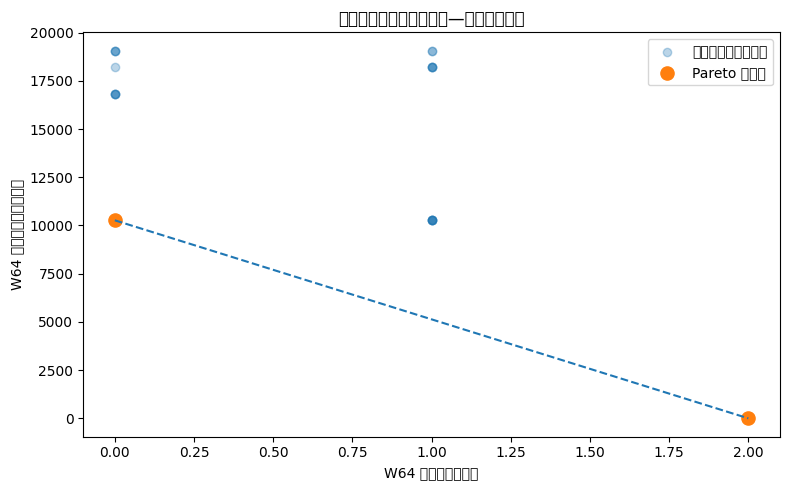

In [6]:
primary = results[results["rule_group"] == "主要多证据政策"].copy()
primary_pareto = pareto(primary)

pareto_points = (
    primary_pareto
    .groupby(["false_review_episodes", "business_exposure"], as_index=False)
    .agg(
        review_week=("review_week", "min"),
        delay_weeks=("delay_weeks", "min"),
        policy_count=("rule_name", "size"),
        policies=("rule_name", lambda s: " / ".join(sorted(set(s)))),
        settings=("strictness", lambda s: " / ".join(sorted(set(s)))),
    )
    .sort_values(["false_review_episodes", "business_exposure"])
    .reset_index(drop=True)
)

print("主要多证据 Pareto 规则数：", len(primary_pareto))
print("不同 Pareto 成本点数：", len(pareto_points))

print("\n全部 Pareto 多证据规则：")
display(primary_pareto)

print("\n合并相同成本后的 Pareto 点：")
display(pareto_points)

plt.figure(figsize=(8, 5))
usable = primary.loc[~primary["missed_by_W77"]]

plt.scatter(
    usable["false_review_episodes"],
    usable["business_exposure"],
    alpha=0.30,
    label="主要多证据候选政策",
)

plt.scatter(
    pareto_points["false_review_episodes"],
    pareto_points["business_exposure"],
    s=90,
    label="Pareto 成本点",
)

if len(pareto_points) > 1:
    p = pareto_points.sort_values("false_review_episodes")
    plt.plot(
        p["false_review_episodes"],
        p["business_exposure"],
        linestyle="--",
    )

plt.xlabel("W64 前误复核事件数")
plt.ylabel("W64 后复核前业务暴露量")
plt.title("多证据复核政策的误复核—业务暴露取舍")
plt.legend()
plt.tight_layout()
plt.show()

## 9.1 多证据政策的核心运行结果

多证据政策最终有 **4 条 Pareto 有效规则**，但它们实际上只形成 **2 个不同成本点**。

### 成本点 A：更保守，等待一周

对应规则包括：

- 至少 2 项异常 + 严格 + 持续 1 周；
- 模型输出异常 + 申请量异常 + 严格 + 持续 1 周。

结果：

- W64 前误复核：0 次；
- W65 启动复核；
- 延迟：1 周；
- 业务暴露：10,268 笔。

### 成本点 B：更敏感，W64 立即行动

对应规则包括：

- 至少 2 项异常 + 宽松 + 持续 1 周；
- 模型输出异常 + 申请量异常 + 宽松 + 持续 1 周。

结果：

- W64 前误复核：2 次；
- W64 启动复核；
- 延迟：0 周；
- 业务暴露：0。

结果体现了以下权衡：

> **更早行动可以减少业务暴露，但会增加误复核；更谨慎可以减少误复核，但会多等待一周。**


# 10. 复核触发时点的指标解释

对 Week 63–65 的四个监控信号分别计算宽松与严格阈值下的异常数量，以解释多证据政策为何在不同周触发。这属于对已保存回测结果的机制分析，不构成独立验证。


In [7]:
focus = signals.loc[
    signals["WEEK_NUM"].isin([63, 64, 65]),
    [
        "WEEK_NUM",
        "score_psi",
        "mean_pd_shift",
        "high_risk_share_shift",
        "volume_shift",
        "application_volume",
    ],
].copy()

def abnormal_count(row, th):
    return sum([
        row["score_psi"] >= th["score_psi"],
        row["mean_pd_shift"] >= th["mean_pd_shift"],
        row["high_risk_share_shift"] >= th["high_risk_share_shift"],
        row["volume_shift"] >= th["volume_shift"],
    ])

focus["宽松_异常项数"] = focus.apply(
    lambda r: abnormal_count(r, THRESHOLDS["宽松"]),
    axis=1,
)

focus["严格_异常项数"] = focus.apply(
    lambda r: abnormal_count(r, THRESHOLDS["严格"]),
    axis=1,
)

display(focus)

for rule_name, level in [
    ("至少2项异常", "宽松"),
    ("至少2项异常", "严格"),
]:
    row = primary_pareto.loc[
        (primary_pareto["rule_name"] == rule_name)
        & (primary_pareto["strictness"] == level)
        & (primary_pareto["persistence_weeks"] == 1)
    ]

    if len(row):
        r = row.iloc[0]
        print(
            f"{rule_name} / {level} / 1周："
            f"误复核={int(r.false_review_episodes)}，"
            f"误复核起始周={r.false_review_start_weeks or '无'}，"
            f"正式复核周=W{int(r.review_week)}"
        )

,WEEK_NUM,score_psi,mean_pd_shift,high_risk_share_shift,volume_shift,application_volume,宽松_异常项数,严格_异常项数
7,63,0.000836,0.008826,0.025703,0.367564,14337,1,0
8,64,0.007161,0.057068,0.112873,0.547057,10268,2,1
9,65,0.038198,0.235510,0.347182,0.812171,4258,3,2


至少2项异常 / 宽松 / 1周：误复核=2，误复核起始周=56, 58，正式复核周=W64
至少2项异常 / 严格 / 1周：误复核=0，误复核起始周=无，正式复核周=W65


## 10.1 指标与触发周数分析

### W64

在宽松阈值下：

- 平均预测概率变化约 5.7%，已经超过 5%；
- 申请量变化约 54.7%，已经超过 20%；
- 因此至少有 2 项异常。

所以“至少 2 项异常 + 宽松 + 1 周”在 W64 就启动复核。

但代价是：它在 W64 以前已经出现过 2 个独立误复核事件。

### W64 在严格阈值下

严格阈值要求：

- 平均预测概率变化达到 15%；
- 申请量变化达到 40%。

W64 时：

- 申请量已经异常；
- 但平均预测概率变化只有约 5.7%；
- 其他信号也没有达到严格阈值。

所以只有 1 项异常，正式复核条件尚未满足。

### W65

W65 时：

- 平均预测概率变化约 23.6%；
- 申请量变化约 81.2%。

严格规则终于同时获得至少 2 项异常证据，因此在 W65 启动复核。

两个 Pareto 成本点对应的机制是：

> **敏感阈值更早积累足够证据，但更容易历史误报；严格阈值需要更多异常程度，因此少误报但晚一周。**


# 11. Pareto 成本偏好情景分析

两个不同 Pareto 成本点允许比较不同的成本权重：

> 如果机构认为一次无效复核“很贵”，或者认为继续让失准模型处理业务“很贵”，最终选择会不会不同？

定义：

`等价成本 = 业务暴露量 + K × 误复核次数`

其中：

`K = 一次无效复核在业务偏好上相当于多少笔业务暴露`

这里不是在调规则，也不是在拟合 W64。

K 仅作为业务成本偏好的情景参数。


In [8]:
K_SCENARIOS = [0, 1000, 5000, 10000, 20000, 50000]

rows = []

for K in K_SCENARIOS:
    temp = pareto_points.copy()
    temp["equivalent_cost"] = (
        temp["business_exposure"]
        + K * temp["false_review_episodes"]
    )

    best = temp["equivalent_cost"].min()
    winners = temp[temp["equivalent_cost"] == best]

    for _, r in winners.iterrows():
        rows.append({
            "K": K,
            "误复核": int(r["false_review_episodes"]),
            "业务暴露": int(r["business_exposure"]),
            "复核周": int(r["review_week"]),
            "等价成本": float(r["equivalent_cost"]),
            "等价政策": r["policies"],
        })

cost_scenarios = pd.DataFrame(rows)
display(cost_scenarios)

# 两个成本点的精确平衡点
a, b = pareto_points.iloc[0], pareto_points.iloc[1]
df = b["false_review_episodes"] - a["false_review_episodes"]
K_STAR = (
    (a["business_exposure"] - b["business_exposure"]) / df
    if df != 0 else np.nan
)

print(f"两个 Pareto 成本点的平衡点：K ≈ {K_STAR:,.0f}")

,K,误复核,业务暴露,复核周,等价成本,等价政策
0,0,2,0,64,0.0,模型输出异常+申请量异常 / 至少2项异常
1,1000,2,0,64,2000.0,模型输出异常+申请量异常 / 至少2项异常
2,5000,2,0,64,10000.0,模型输出异常+申请量异常 / 至少2项异常
3,10000,0,10268,65,10268.0,模型输出异常+申请量异常 / 至少2项异常
4,20000,0,10268,65,10268.0,模型输出异常+申请量异常 / 至少2项异常
5,50000,0,10268,65,10268.0,模型输出异常+申请量异常 / 至少2项异常


两个 Pareto 成本点的平衡点：K ≈ 5,134


## 11.1 成本情景计算结果

两个 Pareto 成本点是：

### 立即行动

- 误复核：2 次；
- 业务暴露：0。

等价成本是：

`2 × K`

### 等待一周

- 误复核：0 次；
- 业务暴露：10,268。

等价成本固定为：

`10,268`

两者相等时：

`2 × K = 10,268`

所以：

> **K ≈ 5,134**

K≈5,134 是两个历史成本点的等价平衡值，并不是独立优化出的最佳参数。

它只是表示：

- 如果一次无效复核在机构看来低于约 5,134 笔业务暴露的代价，W64 立即复核更有吸引力；
- 如果一次无效复核被认为高于约 5,134 笔业务暴露，等待到 W65 更有吸引力。

因此，最终选择不是数据单独决定的，而依赖机构如何评价两种不同成本。


# 12. 结果结论与适用范围

### 12.1 单指标筛查基线

在本次 90 条候选规则中，申请量变化 40% 的单指标规则构成唯一全局 Pareto 解，历史样本里没有提前误复核，且在 W64 当周触发。但该阈值对具体样本时期敏感，不能当成普适阈值。

### 12.2 多证据复核政策

在要求多个证据共同支持复核时，Pareto 前沿有 4 条规则、2 个不同成本点：

| 选择 | 首次复核周 | W64 前误复核事件 | 等待暴露 |
|---|---|---:|---:|
| 宽松、多证据 | W64 | 2 次 | 0 笔 |
| 严格、多证据 | W65 | 0 次 | 10,268 笔 |

若等价成本设为 `业务暴露 + K × 误复核次数`，两个成本点在 **K ≈ 5,134** 时相等。该数值仅为成本情景的平衡点，不是经统计训练得出的最优参数，也不是货币损失。

### 12.3 研究局限

- Week 64 是依据成熟标签在事后选定的近似评价基准。
- 规则集合及其结果只在单一历史变化案例上回放，无法独立验证未来误报率和检出能力。
- 代理信号异常不等同于真实校准失准，申请量也不等同于财务损失。
- 更具迁移价值的是可解释的**监控信号 → 复核规则 → 历史回放 → Pareto / 成本情景**分析流程；独立事件验证仍是后续工作的必要步骤。


In [9]:
# 保存最终结果表

change_points.to_csv(OUT / "01_change_points.csv", index=False)
signals.to_csv(OUT / "02_weekly_monitoring_signals.csv", index=False)
results.to_csv(OUT / "03_all_candidate_rules.csv", index=False)
all_pareto.to_csv(OUT / "04_all_rules_pareto.csv", index=False)
primary_pareto.to_csv(OUT / "05_primary_multi_evidence_pareto.csv", index=False)
pareto_points.to_csv(OUT / "06_primary_pareto_cost_points.csv", index=False)
cost_scenarios.to_csv(OUT / "07_cost_scenarios.csv", index=False)

print("===== 最终结果摘要 =====")
print(f"事后主要变化点：W{TAU}")
print(f"全部规则 Pareto：{len(all_pareto)} 条")
print(f"多证据 Pareto：{len(primary_pareto)} 条，{len(pareto_points)} 个不同成本点")
print(f"成本平衡点：K ≈ {K_STAR:,.0f}")
print("结果保存到：", OUT)

===== 最终结果摘要 =====
事后主要变化点：W64
全部规则 Pareto：1 条
多证据 Pareto：4 条，2 个不同成本点
成本平衡点：K ≈ 5,134
结果保存到： /content/drive/MyDrive/HomeCredit_Project/artifacts/fit5145/nb03_review_tradeoff_v6
